# Fase C — Modelos predictivos supervisados - Regresión

**Proyecto:** Introducción a la Ciencia de Datos · Hurtos por modalidades (Policía Nacional)

**Pregunta de negocio:** ¿es posible predecir la cantidad de hurtos de **motocicletas** que se presentarán en un **municipio** durante el **siguiente mes**, utilizando el comportamiento histórico de los hurtos y las variables disponibles en el dataset?

**Tipo de problema:** regresión (el objetivo es un número: cuántas motos se hurtan).

**Modelos:**
1. Regresión Lineal (el modelo simple y fácil de interpretar)
2. Gradient Boosting (el modelo más flexible, que aprende patrones no lineales)

**Reglas que cumple este notebook**
- Se usa `train_test_split` (80/20) y **todas las métricas se calculan sobre el conjunto de prueba (test)**.
- **No se normaliza antes del split.** El escalado se ajusta solo con los datos de entrenamiento (dentro de un `Pipeline`), para evitar *data leakage*.
- Nunca se evalúa con las mismas filas con las que se entrenó.

In [7]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEMILLA = 42   # misma semilla en todo el notebook -> resultados reproducibles

## 1. Carga de datos

Cargamos `datos_limpios.parquet` (resultado de la fase de limpieza). Cada fila es **un municipio en un mes**.
Ordenamos por municipio y fecha para que el orden temporal sea el correcto.


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

# Ajusta la ruta si tu archivo está en otra carpeta
RUTAS = ["datos_limpios.parquet", "datos/datos_limpios.parquet", "../datos/datos_limpios.parquet"]
ruta = next((r for r in RUTAS if Path(r).exists()), None)
if ruta is None:
    raise FileNotFoundError(f"No encuentro datos_limpios.parquet. Carpeta actual: {Path.cwd()}")

df = (pd.read_parquet(ruta)
        .sort_values(["LLAVE_MUN", "FECHA_MES"])
        .reset_index(drop=True))

print(f"Dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Municipios: {df['LLAVE_MUN'].nunique():,} | Periodo: {df['FECHA_MES'].min():%Y-%m} a {df['FECHA_MES'].max():%Y-%m}")
print(f"Valores nulos: {int(df.isna().sum().sum())}")
df[["LLAVE_MUN", "FECHA_MES", "MOTOS", "MOTOS_LAG1", "MOTOS_PROM3", "MOTOS_LAG12"]].head()

Dataset: 182,350 filas x 64 columnas
Municipios: 1,042 | Periodo: 2012-01 a 2026-07
Valores nulos: 0


,LLAVE_MUN,FECHA_MES,MOTOS,MOTOS_LAG1,MOTOS_PROM3,MOTOS_LAG12
0,AMAZONAS | LETICIA,2012-01-01,1,3.0,1.333333,4.0
1,AMAZONAS | LETICIA,2012-02-01,1,1.0,1.333333,2.0
2,AMAZONAS | LETICIA,2012-03-01,1,1.0,1.666667,1.0
3,AMAZONAS | LETICIA,2012-04-01,2,1.0,1.000000,2.0
4,AMAZONAS | LETICIA,2012-05-01,1,2.0,1.333333,1.0


## 2. Variable objetivo y variables predictoras

**Variable objetivo:** `MOTOS` = hurtos de motocicletas del municipio en el mes que queremos predecir.

**Idea clave para "predecir el siguiente mes":** cada fila representa un mes `t`. Las variables predictoras solo pueden usar información **que ya se conocía antes de que empezara ese mes**:

| Variable | Qué es | ¿Se conoce antes del mes `t`? |
|---|---|---|
| `MOTOS_LAG1` | hurtos de motos del mes anterior | sí |
| `MOTOS_PROM3` | promedio de los 3 meses anteriores | sí |
| `MOTOS_LAG12` | hurtos del mismo mes un año atrás | sí |
| `AUTOS_LAG1` | hurtos de autos del mes anterior | sí |
| `ANIO`, `MES_*` | calendario |sí |
| `DEPARTAMENTO_*`, `ES_CAPITAL_CT` | ubicación del municipio | sí |

**Columnas que NO usamos (y por qué):**
- `MOTOS_LOG`: es el mismo objetivo transformado con logaritmo → daría la respuesta al modelo (*fuga de información*).
- `AUTOS`, `AUTOS_LOG`: hurtos de autos del **mismo** mes, que no conoceríamos al predecir.
- `*_ESC` (variables ya estandarizadas): fueron escaladas con otra partición de los datos. Para cumplir la regla de **no normalizar antes del split**, usamos las variables originales y escalamos después, solo con el train.
- `LLAVE_MUN`, `FECHA_MES`, `CONJUNTO`: identificadores / etiquetas, no son variables predictoras.

In [9]:
TARGET = "MOTOS"

# Verificación anti-fuga: los rezagos deben venir realmente de meses anteriores
g = df.groupby("LLAVE_MUN")[TARGET]
mismo_mun = df["LLAVE_MUN"].eq(df["LLAVE_MUN"].shift(1))
assert (g.shift(1)[mismo_mun] == df["MOTOS_LAG1"][mismo_mun]).all(), "LAG1 no coincide"
prom3 = g.transform(lambda s: s.shift(1).rolling(3).mean())
assert np.allclose(prom3.dropna(), df.loc[prom3.notna(), "MOTOS_PROM3"]), "PROM3 no coincide"
print("Los rezagos usan solo meses anteriores (sin fuga del mes a predecir).")

EXCLUIR = (["LLAVE_MUN", "FECHA_MES", "CONJUNTO", TARGET, "MOTOS_LOG", "AUTOS", "AUTOS_LOG"]
           + [c for c in df.columns if c.endswith("_ESC")])

X = df.drop(columns=EXCLUIR)
y = df[TARGET]

print(f"X: {X.shape[0]:,} filas x {X.shape[1]} variables predictoras")
print(f"y ({TARGET}): media={y.mean():.2f} | mediana={y.median():.0f} | máx={y.max()} | % de meses con 0 hurtos={(y==0).mean():.1%}")

Los rezagos usan solo meses anteriores (sin fuga del mes a predecir).
X: 182,350 filas x 53 variables predictoras
y (MOTOS): media=2.54 | mediana=0 | máx=658 | % de meses con 0 hurtos=70.1%


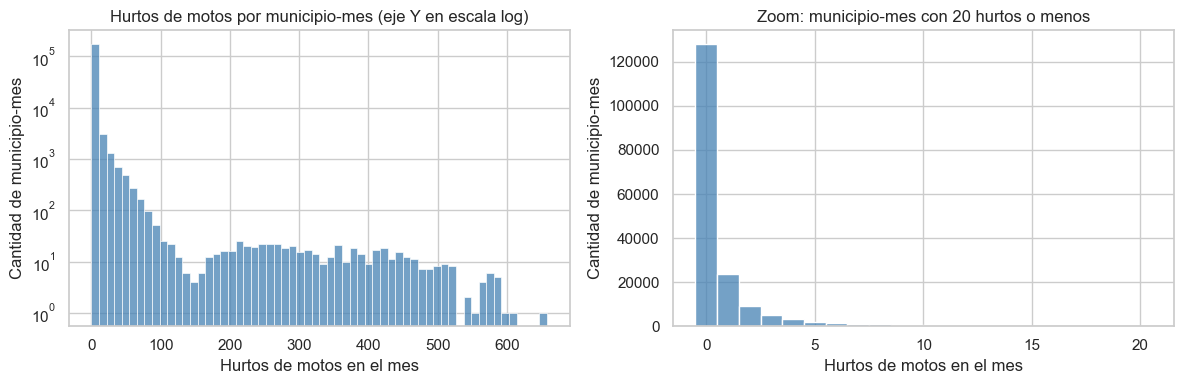

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=60, ax=axes[0], color="steelblue")
axes[0].set_yscale("log")
axes[0].set_title("Hurtos de motos por municipio-mes (eje Y en escala log)")
axes[0].set_xlabel("Hurtos de motos en el mes"); axes[0].set_ylabel("Cantidad de municipio-mes")
sns.histplot(y[y <= 20], bins=21, discrete=True, ax=axes[1], color="steelblue")
axes[1].set_title("Zoom: municipio-mes con 20 hurtos o menos")
axes[1].set_xlabel("Hurtos de motos en el mes"); axes[1].set_ylabel("Cantidad de municipio-mes")
plt.tight_layout(); plt.show()

**Insight:** la mayoría de municipio-mes tiene 0 o muy pocos hurtos, y unas pocas ciudades grandes tienen cientos. Es una distribución muy sesgada. Esto importa porque los errores en las ciudades grandes pesan mucho más en el **RMSE** que en el **MAE**.

## 3. Split Entrenamiento / Prueba (80 / 20)

El split se hace **antes** de cualquier escalado.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA
)

print(f"Train: {len(X_train):,} filas ({len(X_train)/len(X):.0%}) | Test: {len(X_test):,} filas ({len(X_test)/len(X):.0%})")
assert set(X_train.index).isdisjoint(X_test.index), "¡Hay filas repetidas entre train y test!"
print("Ninguna fila está en train y test a la vez.")

Train: 145,880 filas (80%) | Test: 36,470 filas (20%)
Ninguna fila está en train y test a la vez.


## 4. Punto de comparación (baseline)

Antes de entrenar, necesitamos saber **cuánto es "buen resultado"**. El baseline más simple: *"el próximo mes habrá los mismos hurtos que el mes pasado"* (`MOTOS_LAG1`). Si un modelo no supera esto, no aporta valor.

**Métricas** :

| Métrica | Qué significa | Ideal |
|---|---|---|
| **MAE** | error promedio, en "motos hurtadas" | cercano a 0 |
| **RMSE** | como el MAE pero castiga más los errores grandes | cercano a 0 |
| **R²** | % de la variación que el modelo logra explicar | cercano a 1 |

In [12]:
def evaluar(nombre, y_real, y_pred):
    """Calcula las métricas de regresión. Siempre se llama con datos de TEST."""
    return {
        "Modelo": nombre,
        "MAE":  round(mean_absolute_error(y_real, y_pred), 4),
        "RMSE": round(np.sqrt(mean_squared_error(y_real, y_pred)), 4),
        "R²":   round(r2_score(y_real, y_pred), 4),
    }

resultados = [evaluar("Baseline (mes anterior)", y_test, X_test["MOTOS_LAG1"])]
pd.DataFrame(resultados)

,Modelo,MAE,RMSE,R²
0,Baseline (mes anterior),0.9148,3.5724,0.9667


## 5. Modelo 1 — Regresión Lineal

**Idea:** busca la mejor "receta" que suma los aportes de cada variable:

`hurtos ≈ β₀ + β₁·(hurtos mes anterior) + β₂·(promedio 3 meses) + β₃·(mismo mes año pasado) + ... + (efecto departamento) + (efecto mes)`

Cada coeficiente dice cuántos hurtos suben (o bajan) por cada unidad que sube esa variable, manteniendo lo demás constante.

**Sobre el escalado:** la regresión lineal no lo necesita para predecir, pero lo usamos para poder **comparar coeficientes** entre variables. Lo metemos dentro de un `Pipeline`: así el `StandardScaler` se ajusta **solo con X_train** y luego se aplica a X_test. Esto evita el data leakage.

In [17]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),          # se ajusta SOLO con train
    ("regresion", LinearRegression()),
])

modelo_lineal.fit(X_train, y_train)           # aprende con train
y_pred_lin = modelo_lineal.predict(X_test)    # predice en test (datos nunca vistos)

# La regresión lineal puede dar valores negativos; no existen "hurtos negativos"
y_pred_lin_0 = np.clip(y_pred_lin, 0, None)

resultados.append(evaluar("Regresión Lineal", y_test, y_pred_lin))
resultados.append(evaluar("Regresión Lineal (pred. ≥ 0)", y_test, y_pred_lin_0))
print(pd.DataFrame(resultados).to_string(index=False))
print(f"\nPredicciones negativas de la regresión lineal: {(y_pred_lin < 0).mean():.1%} de test")

                      Modelo    MAE   RMSE     R²
     Baseline (mes anterior) 0.9148 3.5724 0.9667
            Regresión Lineal 0.8589 3.1155 0.9747
Regresión Lineal (pred. ≥ 0) 0.8467 3.1150 0.9747

Predicciones negativas de la regresión lineal: 16.3% de test


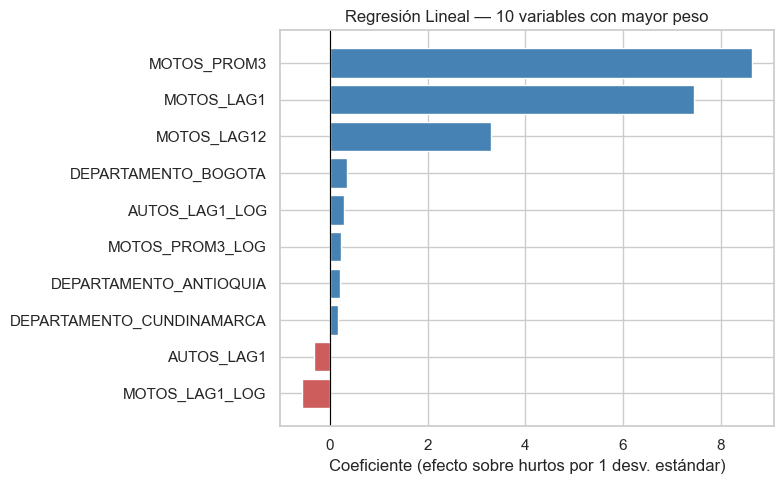

In [18]:
# Variables con mayor peso (coeficientes sobre variables estandarizadas -> son comparables)
coefs = pd.Series(modelo_lineal.named_steps["regresion"].coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=np.where(top.values >= 0, "steelblue", "indianred"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Regresión Lineal — 10 variables con mayor peso")
ax.set_xlabel("Coeficiente (efecto sobre hurtos por 1 desv. estándar)")
plt.tight_layout(); plt.show()

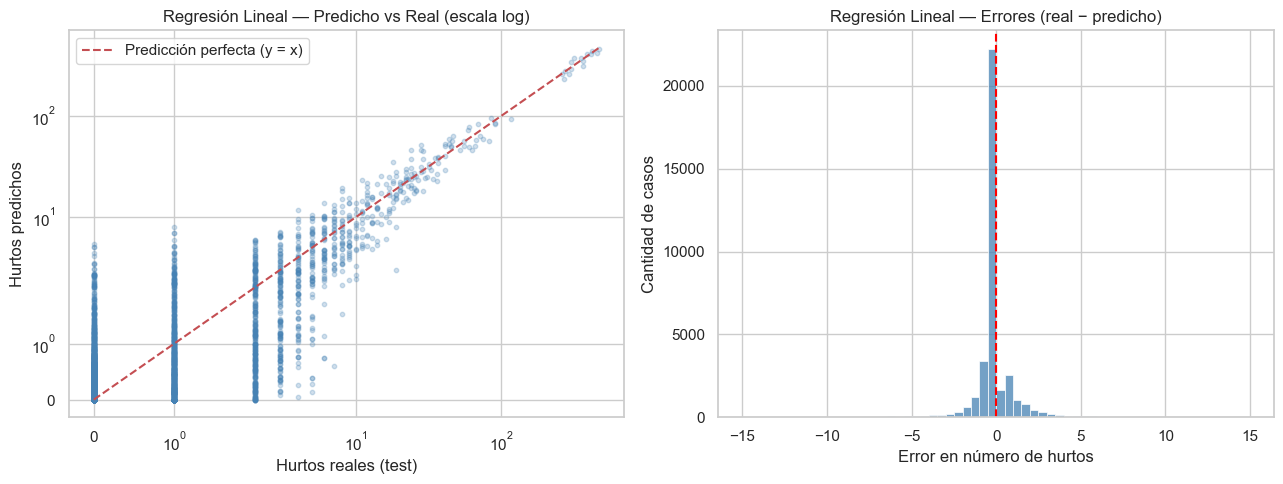

In [19]:
def grafico_pred_vs_real(y_real, y_pred, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    rng = np.random.default_rng(SEMILLA)
    idx = rng.choice(len(y_real), 5000, replace=False)
    yr, yp = np.asarray(y_real)[idx], np.asarray(y_pred)[idx]

    axes[0].scatter(yr, yp, alpha=0.25, s=10, color="steelblue")
    lim = [min(yr.min(), yp.min()), max(yr.max(), yp.max())]
    axes[0].plot(lim, lim, "r--", label="Predicción perfecta (y = x)")
    axes[0].set_xscale("symlog"); axes[0].set_yscale("symlog")
    axes[0].set_xlabel("Hurtos reales (test)"); axes[0].set_ylabel("Hurtos predichos")
    axes[0].set_title(f"{titulo} — Predicho vs Real (escala log)")
    axes[0].legend()

    errores = np.asarray(y_real) - np.asarray(y_pred)
    sns.histplot(errores[np.abs(errores) <= 15], bins=60, ax=axes[1], color="steelblue")
    axes[1].axvline(0, color="red", linestyle="--")
    axes[1].set_title(f"{titulo} — Errores (real − predicho)")
    axes[1].set_xlabel("Error en número de hurtos"); axes[1].set_ylabel("Cantidad de casos")
    plt.tight_layout(); plt.show()

grafico_pred_vs_real(y_test, y_pred_lin_0, "Regresión Lineal")

**Insight:** si los puntos siguen la línea roja, el modelo acierta. Los errores se concentran alrededor de 0 (la mayoría de municipios tiene pocos hurtos y se predicen bien). Los desvíos más grandes ocurren en municipios con muchos hurtos.

## 6. Modelo 2 — Gradient Boosting

**Ventajas frente a la lineal:** captura relaciones **no lineales** (por ejemplo, que el efecto del mes anterior no sea igual en un pueblo pequeño que en Bogotá) y no necesita escalado.
**Desventajas:** menos interpretable y más lento de entrenar.

**Hiperparámetros elegidos:**
- `n_estimators=200` → número de árboles.
- `learning_rate=0.1` → qué tanto corrige cada árbol (más bajo = más cauteloso).
- `max_depth=4` → profundidad de cada árbol; árboles pequeños evitan memorizar.
- `subsample=0.8` → cada árbol ve el 80% de las filas (reduce sobreajuste).



In [20]:
modelo_gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    random_state=SEMILLA,
)

modelo_gb.fit(X_train, y_train)               # aprende con train
y_pred_gb = modelo_gb.predict(X_test)         # predice en test
y_pred_gb_0 = np.clip(y_pred_gb, 0, None)

resultados.append(evaluar("Gradient Boosting", y_test, y_pred_gb))
resultados.append(evaluar("Gradient Boosting (pred. ≥ 0)", y_test, y_pred_gb_0))
print(pd.DataFrame(resultados).to_string(index=False))

                       Modelo    MAE   RMSE     R²
      Baseline (mes anterior) 0.9148 3.5724 0.9667
             Regresión Lineal 0.8589 3.1155 0.9747
 Regresión Lineal (pred. ≥ 0) 0.8467 3.1150 0.9747
            Gradient Boosting 0.8746 3.4127 0.9696
Gradient Boosting (pred. ≥ 0) 0.8746 3.4127 0.9696


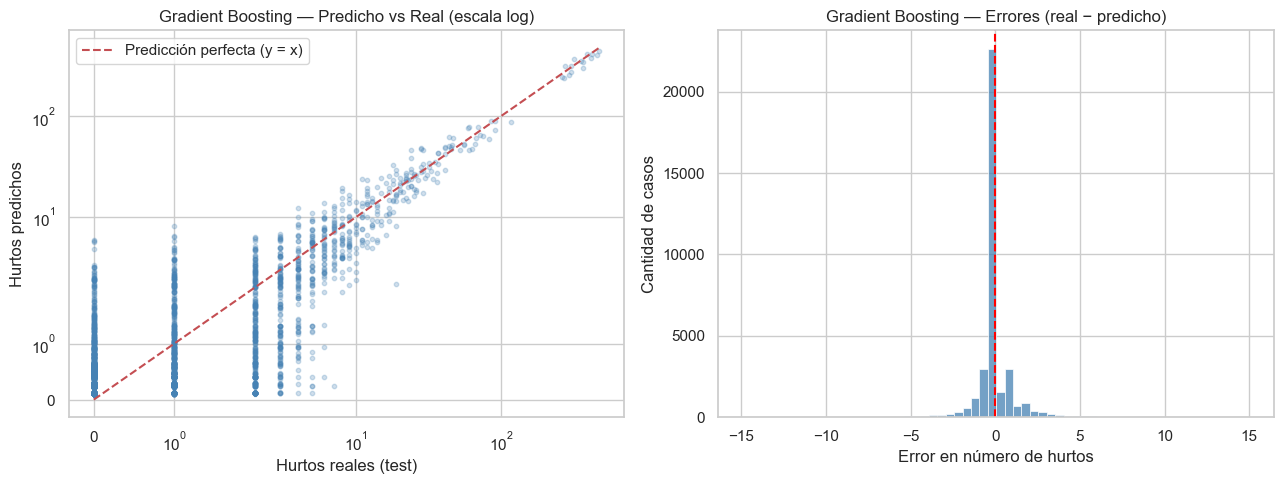

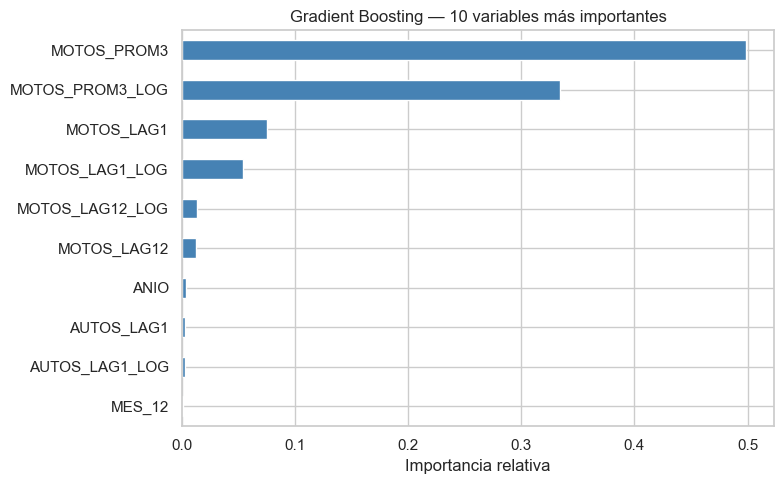

In [21]:
grafico_pred_vs_real(y_test, y_pred_gb_0, "Gradient Boosting")

imp = pd.Series(modelo_gb.feature_importances_, index=X.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot.barh(ax=ax, color="steelblue")
ax.set_title("Gradient Boosting — 10 variables más importantes")
ax.set_xlabel("Importancia relativa")
plt.tight_layout(); plt.show()

**Insight:** las variables que más usa el modelo son las del **comportamiento histórico reciente** (promedio de 3 meses y mes anterior). El departamento y el mes del año aportan muy poco. En otras palabras: *para predecir los hurtos del próximo mes, lo más informativo es mirar cómo vienen los últimos meses.*

## 7. Comparación final de modelos (sobre test)

,Modelo,MAE,RMSE,R²
0,Baseline (mes anterior),0.9148,3.5724,0.9667
1,Regresión Lineal (pred. ≥ 0),0.8467,3.1150,0.9747
2,Gradient Boosting (pred. ≥ 0),0.8746,3.4127,0.9696


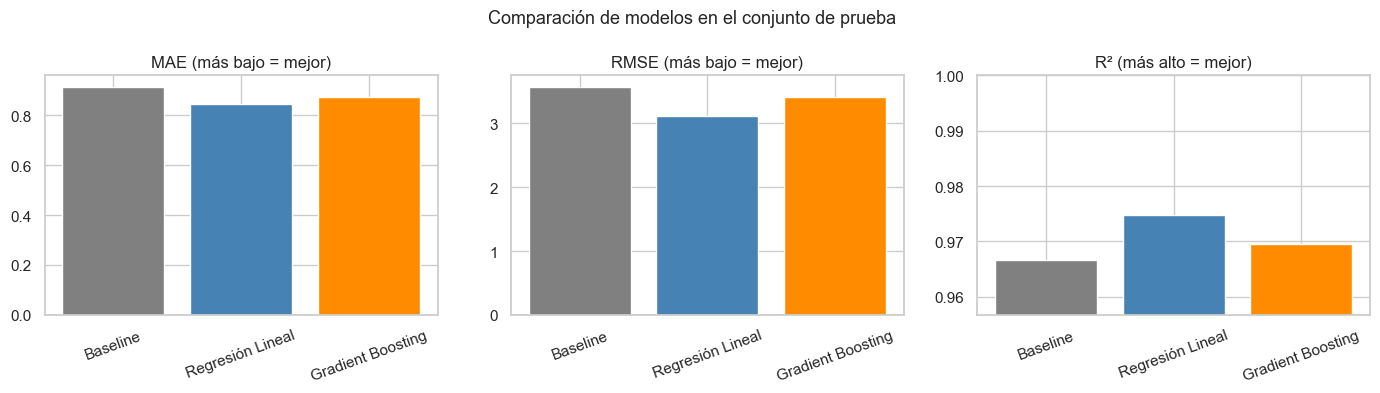

In [22]:
tabla = pd.DataFrame(resultados)
tabla_final = tabla[tabla["Modelo"].isin([
    "Baseline (mes anterior)", "Regresión Lineal (pred. ≥ 0)", "Gradient Boosting (pred. ≥ 0)"
])].reset_index(drop=True)
display(tabla_final)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colores = ["gray", "steelblue", "darkorange"]
for ax, metrica in zip(axes, ["MAE", "RMSE", "R²"]):
    ax.bar(tabla_final["Modelo"].str.replace(" (pred. ≥ 0)", "", regex=False).str.replace(" (mes anterior)", "", regex=False),
           tabla_final[metrica], color=colores)
    ax.set_title(metrica + (" (más alto = mejor)" if metrica == "R²" else " (más bajo = mejor)"))
    ax.tick_params(axis="x", rotation=20)
    if metrica == "R²":
        ax.set_ylim(tabla_final[metrica].min() - 0.01, 1)
plt.suptitle("Comparación de modelos en el conjunto de prueba", fontsize=13)
plt.tight_layout(); plt.show()

## 8. Validación adicional — ¿y si predecimos el **futuro** de verdad?

El `train_test_split` aleatorio mezcla meses de todos los años: el modelo puede entrenar con datos de 2023 y probar en 2019. En la vida real **solo se conoce el pasado**. Por eso hacemos una segunda prueba más exigente y realista:

- **Entrenar** con el periodo 2012 – 2024.
- **Probar** con 2025 – 2026 (meses que el modelo no ha visto y que son *posteriores* al entrenamiento).

Usamos la columna `CONJUNTO` que ya traía el dataset. Los modelos se reentrenan con la misma configuración. Esta sección es complementaria; la evaluación principal del trabajo es la del split 80/20.

In [23]:
es_train = (df["CONJUNTO"] == "train").values
Xt_tr, Xt_te = X[es_train], X[~es_train]
yt_tr, yt_te = y[es_train], y[~es_train]
print(f"Train (2012-2024): {len(Xt_tr):,} filas | Test (2025-2026): {len(Xt_te):,} filas")

lin_t = Pipeline([("escalador", StandardScaler()), ("regresion", LinearRegression())]).fit(Xt_tr, yt_tr)
gb_t = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4,
                                 subsample=0.8, random_state=SEMILLA).fit(Xt_tr, yt_tr)

res_temporal = pd.DataFrame([
    evaluar("Baseline (mes anterior)", yt_te, Xt_te["MOTOS_LAG1"]),
    evaluar("Regresión Lineal", yt_te, np.clip(lin_t.predict(Xt_te), 0, None)),
    evaluar("Gradient Boosting", yt_te, np.clip(gb_t.predict(Xt_te), 0, None)),
])
display(res_temporal)

Train (2012-2024): 162,552 filas | Test (2025-2026): 19,798 filas


,Modelo,MAE,RMSE,R²
0,Baseline (mes anterior),1.0685,4.8288,0.9467
1,Regresión Lineal,0.9684,3.9685,0.9640
2,Gradient Boosting,0.9828,4.3902,0.9560


## 9. Conclusiones

*(Los valores citados corresponden a la ejecución con `random_state=42`; si cambias la semilla pueden variar un poco.)*

1. **Sí es posible predecir** los hurtos de motos del siguiente mes con buena precisión: con el split 80/20 ambos modelos explican cerca del **97% de la variación** (R² ≈ 0.97) y se equivocan, en promedio, menos de **1 moto por municipio-mes** (MAE ≈ 0.85 – 0.87).
2. **Ambos modelos superan al baseline** ("mismo número que el mes pasado"), pero la mejora es moderada: el comportamiento reciente ya contiene casi toda la señal.
3. **La Regresión Lineal quedó ligeramente mejor que Gradient Boosting** (menor RMSE y MAE en test). Es razonable: la relación entre los hurtos recientes y los del próximo mes es casi lineal, y el modelo más flexible no tiene mucho extra que aprender. Con más ajuste de hiperparámetros (por ejemplo, `GridSearchCV`) Gradient Boosting podría mejorar.
4. **La variable que más pesa es el historial reciente** (`MOTOS_PROM3`, `MOTOS_LAG1`). Calendario y departamento aportan poco.
5. **Prueba de futuro (sección 8):** al predecir 2025-2026 con modelos entrenados hasta 2024, el error sube un poco (el futuro siempre es más difícil que una muestra aleatoria), pero ambos modelos siguen superando claramente al baseline. Esa es la cifra más realista para un uso en producción.
6. **Limitaciones:** el dataset está dominado por municipios con pocos hurtos, por eso el MAE luce bajo; el RMSE (mayor) muestra que en ciudades grandes los errores son más altos. Un siguiente paso sería evaluar el error por tamaño de municipio.

### Checklist de requisitos
- [x] `train_test_split` 80/20 aplicado
- [x] Métricas calculadas solo sobre el conjunto de **test**
- [x] Escalado ajustado **solo con train** (dentro de `Pipeline`), nunca antes del split
- [x] Sin fuga de información en las variables (se excluyeron `MOTOS_LOG`, `AUTOS`, `*_ESC`, etc.)
- [x] Dos modelos supervisados: Regresión Lineal y Gradient Boosting